In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score



print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df=pd.read_csv(r"Train.csv")

In [5]:
df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


In [6]:
df.shape

(8523, 12)

In [7]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,1463
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,2410
Outlet_Location_Type,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [9]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [10]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [11]:
# Check unique values
print(df['Item_Fat_Content'].unique())

['Low Fat' 'Regular' 'low fat' 'LF' 'reg']


In [12]:
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})


print(df['Item_Fat_Content'].unique())

['Low Fat' 'Regular']


In [13]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: Item_Identifier
Item_Identifier
FDW13    10
FDG33    10
FDX31     9
FDT07     9
NCY18     9
         ..
FDO33     1
FDK57     1
FDT35     1
FDN52     1
FDE52     1
Name: count, Length: 1559, dtype: int64

Column: Item_Fat_Content
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Column: Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Column: Outlet_Identifier
Outlet_Identifier
OUT027    935
OUT013    932
OUT035    930
OUT049    930
OUT046    930
OUT045    929
OUT018    928
OUT017  

In [14]:

df['Item_Weight'] = df['Item_Weight'].fillna(
    df['Item_Weight'].median()
)

df['Outlet_Size'] = df['Outlet_Size'].fillna(
    df['Outlet_Size'].mode()[0]
)

In [15]:
df.isnull().sum()

,0
Item_Identifier,0
Item_Weight,0
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,0
Outlet_Location_Type,0


In [16]:
print("Dataset Shape:", df.shape)

Dataset Shape: (8523, 12)


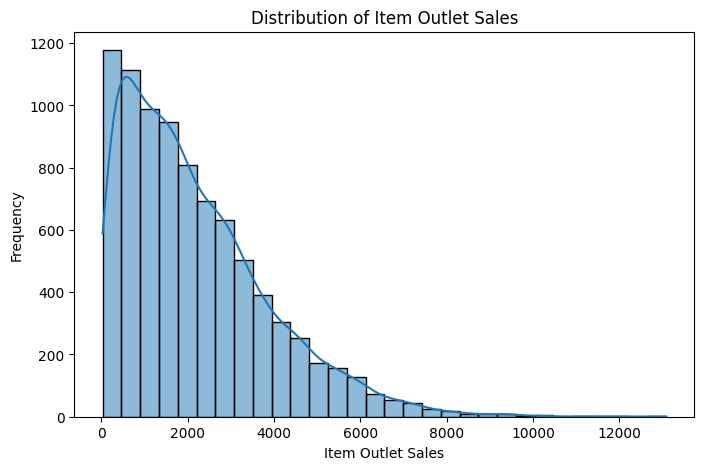

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Item_Outlet_Sales'], bins=30, kde=True)

plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Frequency")

plt.show()

In [18]:
Q1 = df['Item_Outlet_Sales'].quantile(0.25)
Q3 = df['Item_Outlet_Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Item_Outlet_Sales'] < lower_limit) |
    (df['Item_Outlet_Sales'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(outliers))
print("Outlier Percentage:", len(outliers)/len(df)*100)

Lower Limit: -2566.3261
Upper Limit: 6501.8699
Total Outliers: 186
Outlier Percentage: 2.1823301654347063


In [19]:
train_pred = model.predict(X_train)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)

NameError: name 'model' is not defined

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])


rf_model.fit(X_train, y_train)


rf_pred = rf_model.predict(X_test)


rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("-------------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

NameError: name 'Pipeline' is not defined

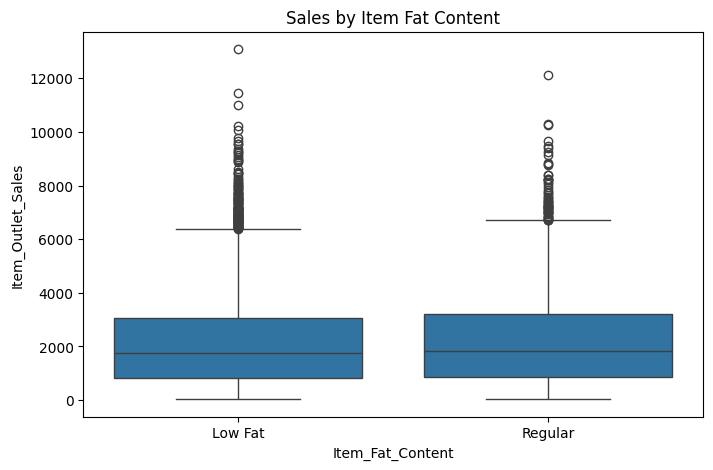

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Item_Fat_Content',
            y='Item_Outlet_Sales')

plt.title("Sales by Item Fat Content")
plt.show()

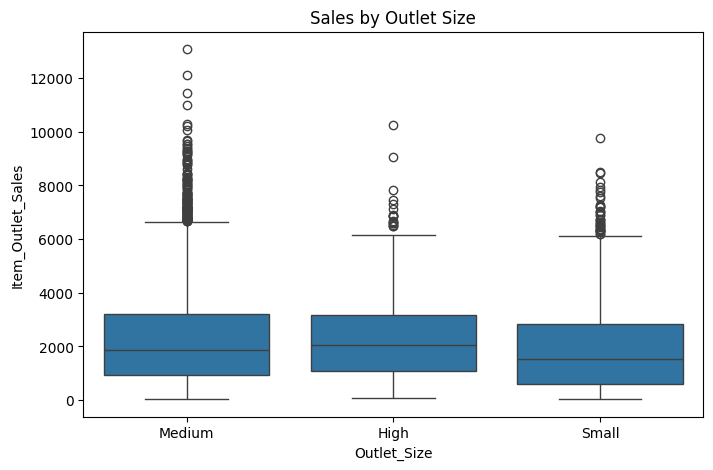

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Outlet_Size',
            y='Item_Outlet_Sales')

plt.title("Sales by Outlet Size")
plt.show()

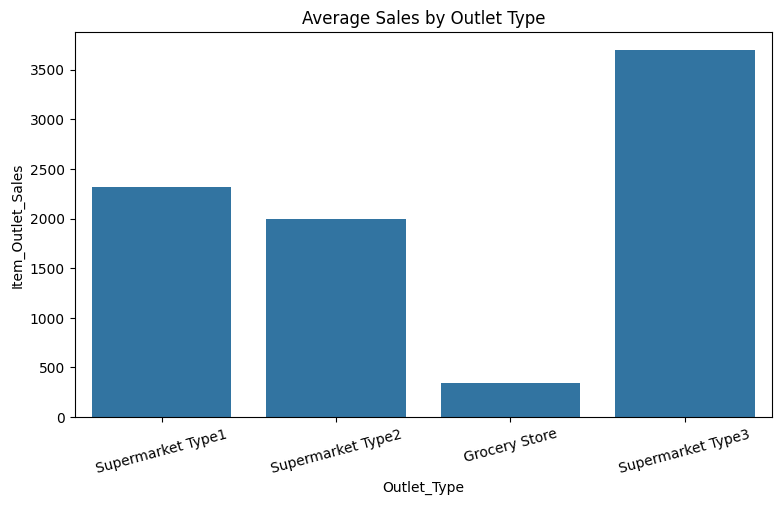

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(data=df, x='Outlet_Type',
            y='Item_Outlet_Sales',
            errorbar=None)

plt.title("Average Sales by Outlet Type")
plt.xticks(rotation=15)
plt.show()

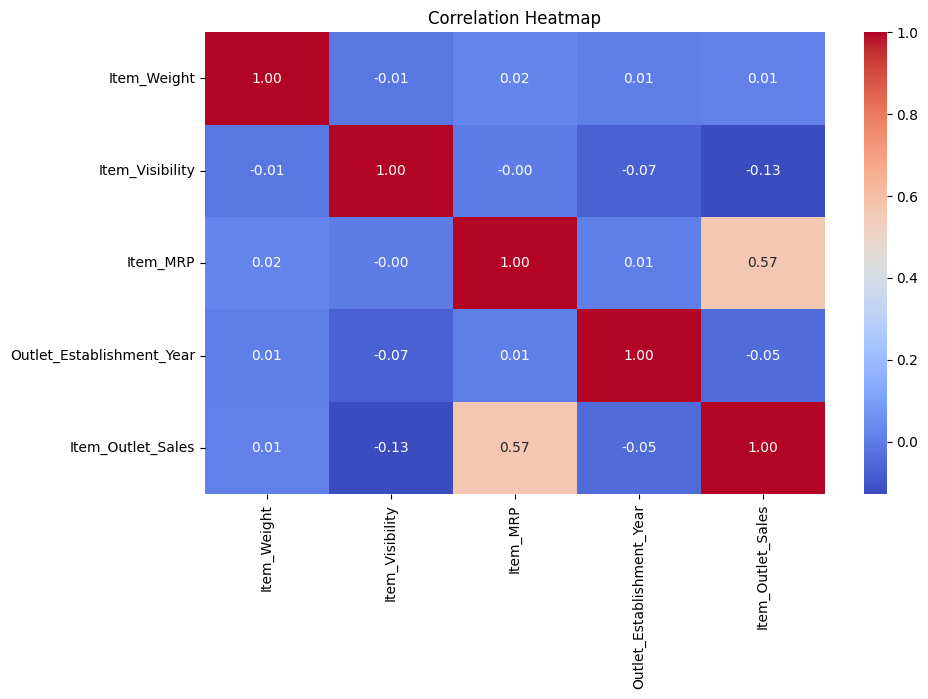

In [24]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

### Correlation Heatmap Analysis

The correlation heatmap was used to identify relationships between numerical features and item outlet sales.

- Item_MRP has the highest positive correlation with sales (0.57).
- Item_Visibility has a weak negative correlation (-0.13).
- Outlet_Establishment_Year has a very weak negative correlation (-0.05).
- Item_Weight has almost zero correlation (0.01).

Therefore, Item_MRP appears to be an important numerical feature for predicting sales.

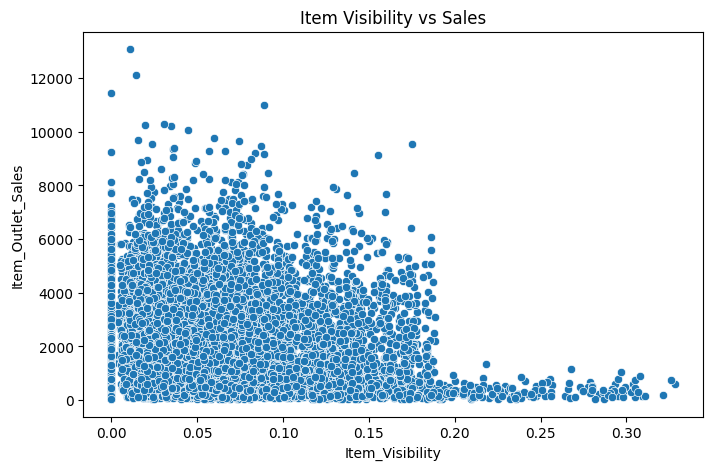

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,
                x='Item_Visibility',
                y='Item_Outlet_Sales')

plt.title("Item Visibility vs Sales")
plt.show()

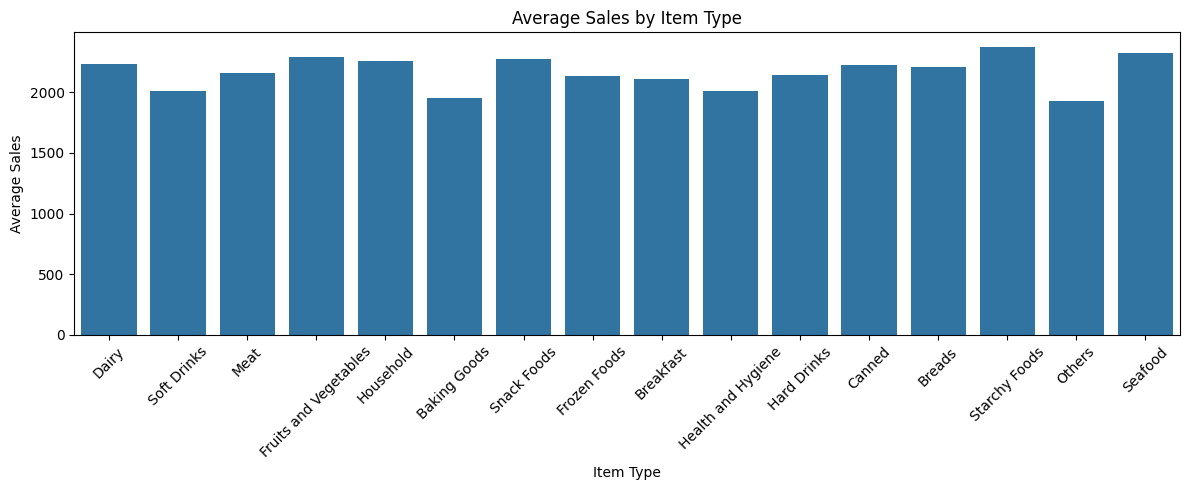

In [26]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x='Item_Type',
    y='Item_Outlet_Sales',
    errorbar=None
)

plt.title("Average Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

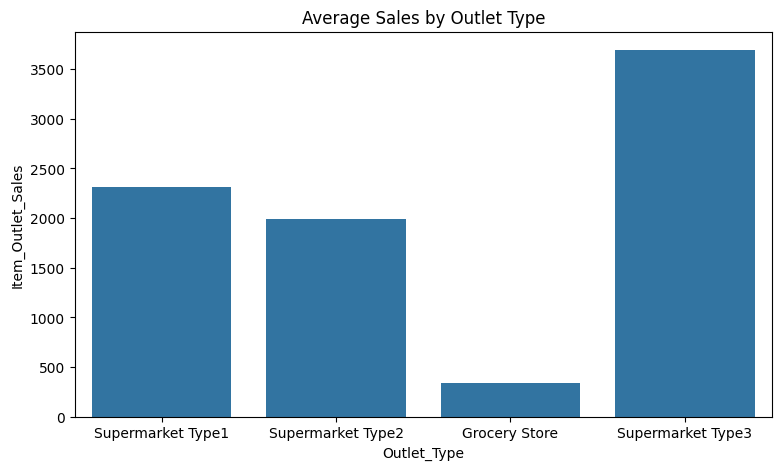

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Outlet_Type',
    y='Item_Outlet_Sales',
    errorbar=None
)

plt.title("Average Sales by Outlet Type")
plt.show()

In [28]:

X = df.drop(
    columns=['Item_Outlet_Sales', 'Item_Identifier']
)


y = df['Item_Outlet_Sales']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (8523, 10)
Target Shape: (8523,)

Input Features:
['Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [29]:

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']

Categorical Features: ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (6818, 10)
Testing Data: (1705, 10)


In [31]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [32]:
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully")

Linear Regression imported successfully


In [33]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print("Model created successfully!")

Model created successfully!


In [34]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [35]:
y_pred = model.predict(X_test)

print("Actual Sales:", y_test.iloc[:10].values)
print("Predicted Sales:", y_pred[:10])

Actual Sales: [1743.0644  356.8688  377.5086 5778.4782 2356.932   865.54   4613.994
 2410.8618 1948.1308 1937.478 ]
Predicted Sales: [1360.89870642  707.29570713  877.40366752 4229.68982191 3347.39997244
  638.04252473 4753.5024047  2048.23915215 1393.22907807 2786.42015055]


In [36]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation
-------------------------
MAE: 792.0249964679122
MSE: 1143542.1516282978
RMSE: 1069.3653031720721
R2 Score: 0.579266098006827


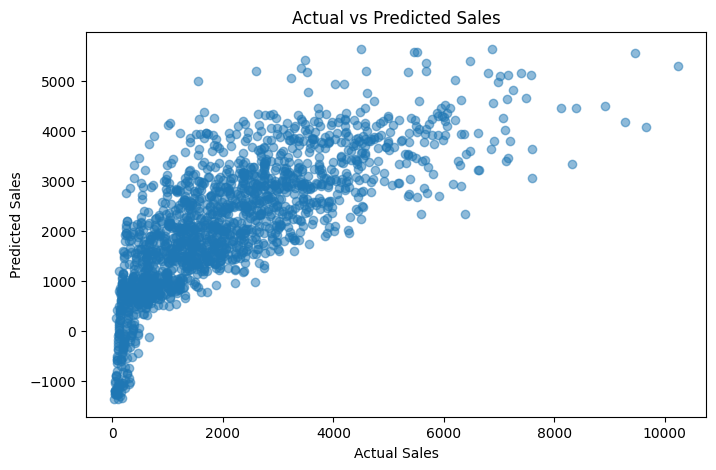

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

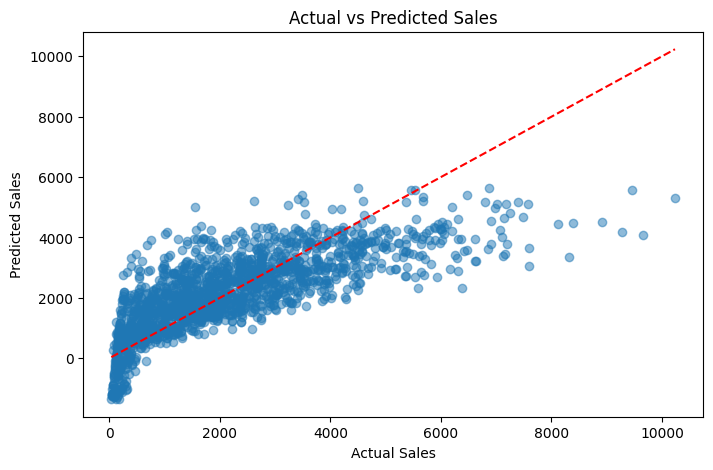

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

In [39]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print(comparison.head(10))

   Actual Sales  Predicted Sales
0     1743.0644      1360.898706
1      356.8688       707.295707
2      377.5086       877.403668
3     5778.4782      4229.689822
4     2356.9320      3347.399972
5      865.5400       638.042525
6     4613.9940      4753.502405
7     2410.8618      2048.239152
8     1948.1308      1393.229078
9     1937.4780      2786.420151


In [41]:
from google.colab import files

files.download("Train.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import os

print(os.listdir('/content'))

['.config', 'Train.csv', 'sample_data']


In [43]:
!ls /content

sample_data  Train.csv
